# StudentScope — Week 3: Statistical Analysis and Classification
**Data Science Virtual Internship | Student Lifestyle & Performance Explorer**

Continuation of Week 1 and Week 2 using the supplied UCI Portuguese-course student dataset. Research question: Do students with different study-time categories have different final grades, and can study habits and background predict whether a student reaches 10/20? The threshold is an analytical definition, not a claim about official promotion rules.

In [1]:
from pathlib import Path
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score
from IPython.display import display
sns.set_theme(style='whitegrid')
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
source = Path('data/student-por.csv')
if not source.exists():
    source = Path('student-por.csv')
if source.exists():
    raw = pd.read_csv(source, sep=';')
else:
    from google.colab import files
    uploaded = files.upload()
    raw = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))), sep=';')
assert raw.shape == (649, 33)
assert not raw.isna().any().any()
print('Original data:', raw.shape)
display(raw.head())

Original data: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


## 1. Reproduce Week 2 cleaning
Preserve original records, normalize selected categories, consolidate mother’s job and recreate the age group. No missing values are present.

In [2]:
df = raw.copy()
for col in ['school','sex','address','internet','famsize','Mjob','Fjob']:
    df[col] = df[col].astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
df['Mjob_group'] = df['Mjob'].map({'teacher':'professional','health':'professional','services':'services','at_home':'home-based','other':'other'}).fillna('unknown')
df['AgeGroup'] = pd.cut(df.age, [0,17,20,np.inf], labels=['Teen (15-17)','Young Adult (18-20)','Adult (21+)'])
assert df.shape == (649,35) and not df.isna().any().any()
assert df.G3.equals(raw.G3)
Path('data').mkdir(exist_ok=True)
df.to_csv('data/survey_clean.csv',index=False)
print('Cleaned data:', df.shape)

Cleaned data: (649, 35)


## 2. Grouped statistics
Compare final grade across the four ordered study-time categories; categories are bands, not exact hours.

,count,mean,median,std
studytime,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


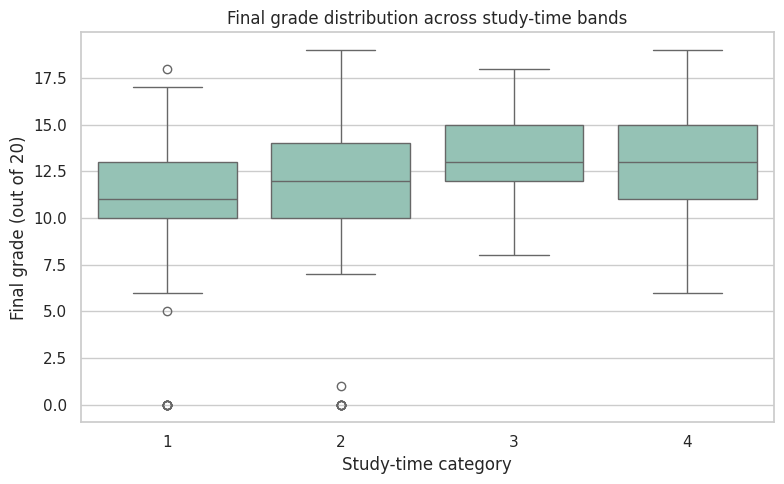

In [3]:
grouped = df.groupby('studytime').G3.agg(['count','mean','median','std'])
display(grouped.round(2))
grouped.to_csv(OUT/'grouped_statistics.csv')
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=df,x='studytime',y='G3',color='#8ec9b8',ax=ax)
ax.set(title='Final grade distribution across study-time bands',xlabel='Study-time category',ylabel='Final grade (out of 20)')
fig.tight_layout(); fig.savefig(OUT/'01_studytime_grade_distribution.png',dpi=180); plt.show()

## 3. Statistical comparison
Compare category 1 with categories 2–4 combined, a defined contrast of lowest versus higher study-time bands. Welch’s t-test permits unequal variances. Cohen’s d describes standardized mean difference. Observational associations are not causal; independence is assumed and school-level clustering is not modeled.

In [4]:
low = df.loc[df.studytime == 1,'G3']
higher = df.loc[df.studytime > 1,'G3']
test = ttest_ind(higher,low,equal_var=False)
gap = higher.mean()-low.mean()
pooled = np.sqrt(((len(low)-1)*low.var()+(len(higher)-1)*higher.var())/(len(low)+len(higher)-2))
d = gap/pooled
print(f'Lowest band: n={len(low)}, mean={low.mean():.2f}, median={low.median():.2f}')
print(f'Higher bands: n={len(higher)}, mean={higher.mean():.2f}, median={higher.median():.2f}')
print(f'Higher minus lowest: {gap:.2f} grade points; Welch t={test.statistic:.3f}, p={test.pvalue:.4g}, Cohen d={d:.3f}')
print('Evidence of a mean difference at 5% significance.' if test.pvalue<.05 else 'Insufficient evidence of a mean difference at 5% significance.')

Lowest band: n=212, mean=10.84, median=11.00
Higher bands: n=437, mean=12.42, median=13.00
Higher minus lowest: 1.58 grade points; Welch t=5.916, p=7.015e-09, Cohen d=0.501
Evidence of a mean difference at 5% significance.


## 4. Target, features and held-out split
Predict grade band using five features: study time, previous failures, travel time, internet access and grouped mother’s job. Exclude G1, G2 and G3 from predictors to avoid using grades or the target itself. Fit preprocessing on training data only.

In [5]:
df['grade_band'] = np.where(df.G3>=10,'10 or above','Below 10')
labels = ['Below 10','10 or above']
numeric = ['studytime','failures','traveltime']
categorical = ['internet','Mjob_group']
X = df[numeric+categorical]
y = df.grade_band
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('Train:',len(X_train),'Test:',len(X_test))
display(pd.DataFrame({'train':y_train.value_counts(),'test':y_test.value_counts()}))
def preprocess():
    return ColumnTransformer([('num',StandardScaler(),numeric),('cat',OneHotEncoder(handle_unknown='ignore'),categorical)])
model = Pipeline([('prepare',preprocess()),('classifier',LogisticRegression(max_iter=1000,random_state=42))])
model.fit(X_train,y_train)
pred = model.predict(X_test)

Train: 519 Test: 130


,train,test
grade_band,,
10 or above,439,110
Below 10,80,20


## 5. Classification report and confusion matrix
Rows of the matrix are actual categories and columns are predictions. Compare accuracy with a majority-class baseline and examine recall for each grade band.

              precision    recall  f1-score   support

    Below 10       0.00      0.00      0.00        20
 10 or above       0.84      0.99      0.91       110

    accuracy                           0.84       130
   macro avg       0.42      0.50      0.46       130
weighted avg       0.71      0.84      0.77       130

Accuracy: 83.85%; majority baseline: 84.62%; balanced accuracy: 49.55%


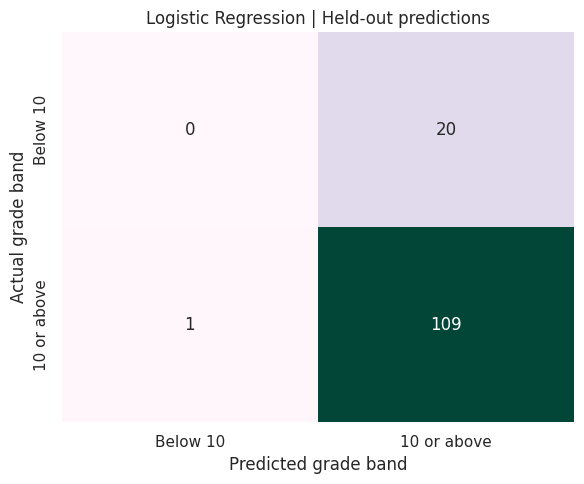

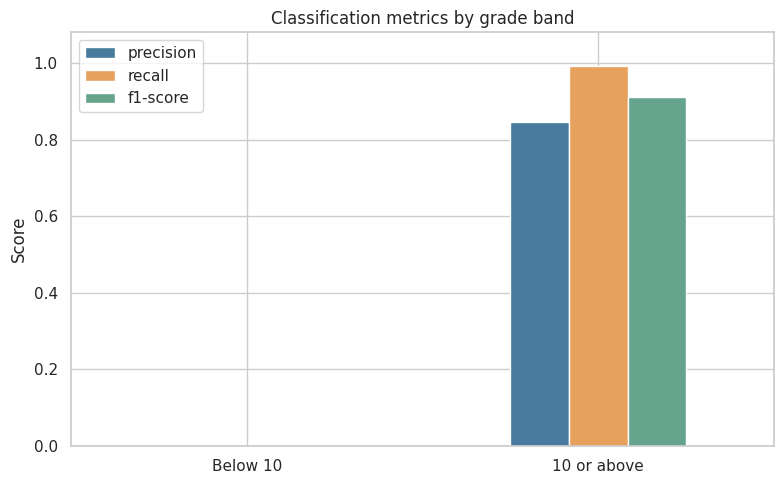

In [6]:
report = classification_report(y_test,pred,labels=labels,output_dict=True,zero_division=0)
print(classification_report(y_test,pred,labels=labels,zero_division=0))
pd.DataFrame(report).T.to_csv(OUT/'classification_report.csv')
cm = confusion_matrix(y_test,pred,labels=labels)
accuracy = accuracy_score(y_test,pred)
baseline = (y_test == y_train.mode().iloc[0]).mean()
print(f'Accuracy: {accuracy:.2%}; majority baseline: {baseline:.2%}; balanced accuracy: {balanced_accuracy_score(y_test,pred):.2%}')
fig,ax=plt.subplots(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='PuBuGn',xticklabels=labels,yticklabels=labels,ax=ax,cbar=False)
ax.set(xlabel='Predicted grade band',ylabel='Actual grade band',title='Logistic Regression | Held-out predictions')
fig.tight_layout();fig.savefig(OUT/'02_grade_confusion_matrix.png',dpi=180);plt.show()
metrics=pd.DataFrame(report).T.loc[labels,['precision','recall','f1-score']]
ax=metrics.plot.bar(figsize=(8,5),rot=0,ylim=(0,1.08),color=['#477a9c','#e6a15c','#65a38c'])
ax.set(ylabel='Score',title='Classification metrics by grade band')
fig=ax.figure;fig.tight_layout();fig.savefig(OUT/'03_grade_classification_metrics.png',dpi=180);plt.show()

## 6. Interpretation and optional model comparison

In [7]:
worst = min(labels,key=lambda k:report[k]['recall'])
i=labels.index(worst)
interpretation = (f'Logistic Regression correctly classified {cm.trace()} of {cm.sum()} test students ({accuracy:.2%}), compared with a majority baseline of {baseline:.2%}. '
                  f'It struggled most with {worst}, whose recall was {report[worst]["recall"]:.2%}. '
                  f'The confusion matrix shows {cm[i,i]} correctly identified and {cm[i,1-i]} misclassified students in that band. '
                  'The model is an educational baseline, not a reliable tool for high-stakes decisions about students.')
print(interpretation)
(OUT/'interpretation.txt').write_text(interpretation,encoding='utf-8')
rf=Pipeline([('prepare',preprocess()),('classifier',RandomForestClassifier(n_estimators=200,min_samples_leaf=5,random_state=42))])
rf.fit(X_train,y_train)
rf_pred=rf.predict(X_test)
minority=y_train.value_counts().idxmin()
comparison=pd.DataFrame([{'model':name,'accuracy':accuracy_score(y_test,pr),'balanced_accuracy':balanced_accuracy_score(y_test,pr),'minority_recall':classification_report(y_test,pr,output_dict=True,zero_division=0)[minority]['recall']} for name,pr in [('Logistic Regression',pred),('Random Forest',rf_pred)]])
display(comparison.round(3))
comparison.to_csv(OUT/'model_comparison.csv',index=False)
print('Minority class:',minority)
print('Highest minority recall:', ', '.join(comparison.loc[comparison.minority_recall==comparison.minority_recall.max(),'model']))

Logistic Regression correctly classified 109 of 130 test students (83.85%), compared with a majority baseline of 84.62%. It struggled most with Below 10, whose recall was 0.00%. The confusion matrix shows 0 correctly identified and 20 misclassified students in that band. The model is an educational baseline, not a reliable tool for high-stakes decisions about students.


,model,accuracy,balanced_accuracy,minority_recall
0,Logistic Regression,0.838,0.495,0.00
1,Random Forest,0.831,0.511,0.05


Minority class: Below 10
Highest minority recall: Random Forest


## 7. Conclusion
This analysis extends the earlier study-time comparison to significance testing and prediction. The sample is limited to two Portuguese schools; results may not generalize. Study-time bands are self-reported categories. The test split is used for descriptive comparison, not hyperparameter selection.

In [8]:
summary=f"""# StudentScope Week 3 results

- Records: {len(df)}; training: {len(X_train)}; testing: {len(X_test)}.
- Lowest study-time mean: {low.mean():.2f}; higher bands mean: {higher.mean():.2f}; difference: {gap:.2f} points.
- Welch t: {test.statistic:.3f}; p: {test.pvalue:.4g}; Cohen d: {d:.3f}.
- {interpretation}
"""
(OUT/'RESULTS.md').write_text(summary,encoding='utf-8')
print(summary)
assert all((OUT/f).exists() for f in ['01_studytime_grade_distribution.png','02_grade_confusion_matrix.png','03_grade_classification_metrics.png','classification_report.csv','interpretation.txt'])
print('All required analysis outputs generated.')

# StudentScope Week 3 results

- Records: 649; training: 519; testing: 130.
- Lowest study-time mean: 10.84; higher bands mean: 12.42; difference: 1.58 points.
- Welch t: 5.916; p: 7.015e-09; Cohen d: 0.501.
- Logistic Regression correctly classified 109 of 130 test students (83.85%), compared with a majority baseline of 84.62%. It struggled most with Below 10, whose recall was 0.00%. The confusion matrix shows 0 correctly identified and 20 misclassified students in that band. The model is an educational baseline, not a reliable tool for high-stakes decisions about students.

All required analysis outputs generated.
